In [21]:
try:
    import h2o
except:
    !pip install -qq -U h2o
    import h2o

from h2o import H2OFrame
from h2o.automl import H2OAutoML

print("h2o version:", h2o.__version__)

h2o version: 3.46.0.12


In [22]:
## -- System dependencies --
import sys, os, gc
import torch

## -- Device-Agnostic (GPU/CPU) --
def get_system_info():
    if torch.cuda.is_available():
        return f"GPU: {torch.cuda.get_device_name(0)}"
    else:
        return f"CPU: {os.cpu_count()}"

get_system_info()

'CPU: 4'

In [23]:
## -- Data Manipulation --
import numpy as np, pandas as pd, random

## -- Visualization --
from IPython.display import display, Image
import matplotlib.pyplot as plt
import seaborn as sns
# import shap

## -- Functional Tools --
import itertools
from tqdm.auto import tqdm
from time import time, sleep

## -- Machine Learning --
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.utils.class_weight import compute_class_weight
from sklearn.calibration import CalibratedClassifierCV, CalibrationDisplay
from sklearn.model_selection import KFold, StratifiedKFold, train_test_split
from sklearn.metrics import roc_auc_score, log_loss, RocCurveDisplay, ConfusionMatrixDisplay
from sklearn.preprocessing import OneHotEncoder, LabelEncoder, label_binarize, TargetEncoder as skTE

import warnings
warnings.simplefilter('ignore')
warnings.filterwarnings('ignore')

## -- Global Settings --
# sklearn.set_config(transform_output='pandas')

# pd.options.mode.copy_on_write = True
pd.set_option('display.max_columns', 100)
# sns.set_style("whitegrid")
# plt.style.use('ggplot')

warnings

<module 'warnings' from '/usr/lib/python3.13/warnings.py'>

In [24]:
TEAL, GOLD, CORAL, BLUE, DARK, CRIM, MUTED, INK, PAPER = '#168c91','#e8b44f','#dc705a',\
                                                         'dodgerblue','#0B4F7A','crimson',\
                                                         '#627D98','#102A43','#faf9f5'
plt.rcParams.update({
    'figure.facecolor': PAPER,
    'axes.facecolor': PAPER,
    'savefig.facecolor': PAPER,
    'font.family': 'DejaVu Sans',
    'font.size': 9,
    'axes.titlesize': 12,
    'axes.titleweight': 'semibold',
    'axes.labelcolor': INK,
    'text.color': INK,
    'xtick.color': DARK,
    'ytick.color': DARK,
    'axes.edgecolor': MUTED,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.color': MUTED,
    'patch.edgecolor': DARK,
    # 'patch.force_edgecolor': True,
    # 'patch.linewidth': 1.5,
    # 'figure.dpi':110,
    # 'savefig.dpi':160,
})
# CMAP = LinearSegmentedColormap.from_list('atlas', ['#f0f5ef','#a9d6ca',TEAL,INK])
sns.set_palette([TEAL, GOLD, CORAL, BLUE, MUTED, CRIM, DARK, INK, PAPER])

## -- Set Global Seed --
CFG = {
    'FOLDS':  5,
    'SEED':   42,
    'GREEN':  '\033[32m',
    'YELLOW': '\033[33m',
    'RESET':  '\033[0m'
}

print(f"CLASSIC {CFG['GREEN']} GREEN {CFG['RESET']} {CFG['YELLOW']} YELLOW {CFG['RESET']}")

CLASSIC  GREEN   YELLOW 


In [25]:
## -- ⚠️ IMPORTANT: SELECT PLATFORM ⚠️ --
PLATFORM = "kaggle" # -> 'colab' 'kaggle'

if PLATFORM == "kaggle":
    PATH = "/kaggle/input/competitions/playground-series-s6e10/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train = pd.read_csv(PATH+"train.csv")
    test = pd.read_csv(PATH+"test.csv")

    ORIG_PATH = "/kaggle/input/datasets/arseniyshutko/binary-aviation-satisfaction-129k/"
    orig = pd.read_csv(ORIG_PATH+"data.csv")
elif PLATFORM == "colab":
    from google.colab import drive
    drive.mount("/content/drive")

    PATH   = "/content/drive/MyDrive/-- shared_notebooks --/Ps6e10 | Airline Satisfaction/_airline_data/"
    submit = pd.read_csv(PATH+"sample_submission.csv")
    train  = pd.read_csv(PATH+"train.csv")
    test   = pd.read_csv(PATH+"test.csv")
    orig   = pd.read_csv(PATH+"data.csv")

## =================================================================================

TARGET, ID = 'satisfaction', 'id'

train[TARGET] = train[TARGET].map({True: 1, False: 0})
orig[TARGET] = orig[TARGET].map({True: 1, False: 0})

obj = train.select_dtypes(include=["object", "category"]).columns.tolist()

cat_cols  = [c for c in obj if c not in [TARGET, ID]]
num_cols  = [c for c in train.columns if c not in cat_cols+[TARGET, ID]]
base_cols = [c for c in train.columns if c not in [TARGET, ID]]

service_cols = [
    'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking',
    'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
    'Inflight entertainment', 'On-board service', 'Leg room service',
    'Baggage handling', 'Checkin service', 'Cleanliness'
]

train = train[base_cols+[TARGET]]
orig  = orig[base_cols+[TARGET]]
test  = test[base_cols]

print(f"Frame type: {type(train)}\n")

for (name, df) in {"Train": train, "Test": test, 'Orig': orig}.items(): #
    print(f"{name} shape: {df.shape}")

print(f"Total Numerical: {len(num_cols)}")
print(f"Total Categorical: {len(cat_cols)}")
print(f"Total base features: {len(base_cols)}")

Frame type: <class 'pandas.core.frame.DataFrame'>

Train shape: (699635, 22)
Test shape: (299844, 21)
Orig shape: (129880, 22)
Total Numerical: 17
Total Categorical: 4
Total base features: 21


In [26]:
train[num_cols] = train[num_cols].fillna(0)
test[num_cols] = test[num_cols].fillna(0)
orig[num_cols] = orig[num_cols].fillna(0)

train.isna().sum()

Age                                  0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
Gender                               0
Customer Type                        0
Type of Travel                       0
Class                                0
satisfaction                         0
dtype: int64

In [27]:
train_len = len(train)
test_len  = len(test)

n_unique = train.nunique().sort_values()
n_unique

satisfaction                            2
Type of Travel                          2
Customer Type                           2
Gender                                  2
Class                                   3
Baggage handling                        5
Gate location                           6
Departure/Arrival time convenient       6
Leg room service                        6
Checkin service                         6
On-board service                        6
Inflight wifi service                   6
Food and drink                          6
Online boarding                         6
Seat comfort                            6
Ease of Online booking                  6
Inflight entertainment                  6
Cleanliness                             6
Age                                    75
Departure Delay in Minutes            167
Arrival Delay in Minutes              168
Flight Distance                      3474
dtype: int64

In [28]:
def get_class_weights(y):
    """
    y: Current y labels -> numpy array or series
    """
    cls_ = np.unique(y)
    wts_ = compute_class_weight("balanced", classes=cls_, y=y)
    return dict(zip(cls_, wts_))

def get_sample_weights(y, y_true, opt='auto'):
    """
    y: Current y labels -> numpy array or series
    y_true: True labels -> numpy array or series
    opt: 'auto' generate weight or pass a custom dict -> label: weight
    """
    if opt != 'auto':
        return np.array([opt[label] for label in y])
    else:
        cls_ = np.unique(y_true)
        wts_ = compute_class_weight('balanced', classes=cls_, y=y_true)
        cls_wts = dict(zip(cls_, wts_))
        return np.array([cls_wts[label] for label in y])

print('- Helper functions ready -')

- Helper functions ready -


## FEATURE ENGINEERING

In [29]:
from sklearn.base import BaseEstimator, TransformerMixin ## ===== Target/Category Mean ENCODERS =====

class TargetEncoder(BaseEstimator, TransformerMixin):
    """
    Target Encoder that supports multiple aggregation functions,
    internal cross-validation for leakage prevention, and smoothing.

    Parameters
    ----------
    cols_to_encode : list of str
        List of column names to be target encoded.

    aggs : list of str, default=['mean']
        List of aggregation functions to apply. Any function accepted by
        pandas' `.agg()` method is supported, such as:
        'mean', 'std', 'var', 'min', 'max', 'skew', 'nunique', 
        'count', 'sum', 'median'.
        Smoothing is applied only to the 'mean' aggregation.

    cv : int, default=5
        Number of folds for cross-validation in fit_transform.

    smooth : float or 'auto', default='auto'
        The smoothing parameter `m`. A larger value puts more weight on the 
        global mean. If 'auto', an empirical Bayes estimate is used.
        
    drop_original : bool, default=False
        If True, the original columns to be encoded are dropped.
    """
    def __init__(self, cols_to_encode, aggs=['mean'], cv=5, smooth='auto', drop_original=False):
        self.cols_to_encode = cols_to_encode
        self.aggs = aggs
        self.cv = cv
        self.smooth = smooth
        self.drop_original = drop_original
        self.mappings_ = {}
        self.global_stats_ = {}

    def fit(self, X, y):
        """
        Learn mappings from the entire dataset.
        These mappings are used for the transform method on validation/test data.
        """
        temp_df = X.copy()
        temp_df['target'] = y

        # Learn global statistics for each aggregation
        for agg_func in self.aggs:
            self.global_stats_[agg_func] = y.agg(agg_func)

        # Learn category-specific mappings
        for col in self.cols_to_encode:
            self.mappings_[col] = {}
            for agg_func in self.aggs:
                mapping = temp_df.groupby(col)['target'].agg(agg_func)
                self.mappings_[col][agg_func] = mapping
        
        return self

    def transform(self, X):
        """
        Apply learned mappings to the data.
        Unseen categories are filled with global statistics.
        """
        X_transformed = X.copy()
        for col in self.cols_to_encode:
            for agg_func in self.aggs:
                new_col_name = f"TE_{col}_{agg_func}"
                map_series = self.mappings_[col][agg_func]
                X_transformed[new_col_name] = X[col].map(map_series)
                X_transformed[new_col_name].fillna(self.global_stats_[agg_func], inplace=True)
        
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed

    def fit_transform(self, X, y):
        """
        Fit and transform the data using internal cross-validation to prevent leakage.
        """
        # First, fit on the entire dataset to get global mappings for transform method
        self.fit(X, y)

        # Initialize an empty DataFrame to store encoded features
        encoded_features = pd.DataFrame(index=X.index)
        
        kf = KFold(n_splits=self.cv, shuffle=True, random_state=42)

        for train_idx, val_idx in kf.split(X, y):
            X_train, y_train = X.iloc[train_idx], y.iloc[train_idx]
            X_val = X.iloc[val_idx]
            
            temp_df_train = X_train.copy()
            temp_df_train['target'] = y_train

            for col in self.cols_to_encode:
                # --- Calculate mappings only on the training part of the fold ---
                for agg_func in self.aggs:
                    new_col_name = f'TE_{col}_{agg_func}'
                    
                    # Calculate global stat for this fold
                    fold_global_stat = y_train.agg(agg_func)
                    
                    # Calculate category stats for this fold
                    mapping = temp_df_train.groupby(col)['target'].agg(agg_func)

                    # --- Apply smoothing only for 'mean' aggregation ---
                    if agg_func == 'mean':
                        counts = temp_df_train.groupby(col)['target'].count()
                        
                        m = self.smooth
                        if self.smooth == 'auto':
                            # Empirical Bayes smoothing
                            variance_between = mapping.var()
                            avg_variance_within = temp_df_train.groupby(col)['target'].var().mean()
                            if variance_between > 0:
                                m = avg_variance_within / variance_between
                            else:
                                m = 0  # No smoothing if no variance between groups
                        
                        # Apply smoothing formula
                        smoothed_mapping = (counts * mapping + m * fold_global_stat) / (counts + m)
                        encoded_values = X_val[col].map(smoothed_mapping)
                    else:
                        encoded_values = X_val[col].map(mapping)
                    
                    # Store encoded values for the validation fold
                    encoded_features.loc[X_val.index, new_col_name] = encoded_values.fillna(fold_global_stat)

        # Merge with original DataFrame
        X_transformed = X.copy()
        for col in encoded_features.columns:
            X_transformed[col] = encoded_features[col]
            
        if self.drop_original:
            X_transformed.drop(columns=self.cols_to_encode, inplace=True)
            
        return X_transformed


class CategoryMeanTransformer(BaseEstimator, TransformerMixin):
    def __init__(self, cat_cols=None):
        self.cat_cols = cat_cols
        self.mappings_ = {}
    def fit(self, X, y):
        X = X.copy()
        if self.cat_cols is None:
            self.cat_cols = X.select_dtypes(include=['category']).columns.tolist()
        self.mappings_ = {}
        for col in self.cat_cols:
            df_temp = pd.DataFrame({col: X[col], 'y': y})
            group_means = df_temp.groupby(col, dropna=False)['y'].mean()
            sorted_categories = group_means.sort_values().index
            self.mappings_[col] = {cat: i for i, cat in enumerate(sorted_categories)}
        return self

    def transform(self, X, y=None):
        X = X.copy()
        for col, mapping in self.mappings_.items():
            if col in X.columns:
                X[col] = X[col].map(mapping)
        return X

In [30]:
def original_TE(
    orig: pd.DataFrame,
    df: pd.DataFrame,
    features: list=None,
    target: str=None,
    aggs: list=None,
    fill_nan: bool=False,
):

    if features is None or len(features) == 0:
        return df.copy()

    if aggs is None or len(aggs) == 0:
        return df.copy()

    X_df = df.copy()

    orig_cols = []
    maps = {}

    valid_features = [col for col in features if col in orig.columns]

    for col in tqdm(valid_features, desc="original_augmenting"):
        for agg_ in aggs:
            agg_key = agg_.lower()
            new_col = f"oTE_{col}_{agg_key}"

            map_key = (col, agg_key)
            if map_key not in maps:
                try:
                    if agg_key == 'mean':
                        map_df = (orig.groupby(col)[target].mean().reset_index(name=new_col))
                    elif agg_key == 'median':
                        map_df = (orig.groupby(col)[target].median().reset_index(name=new_col))
                    elif agg_key == 'count':
                        map_df = (orig.groupby(col).size().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'nunique':
                        map_df = (orig.groupby(col)[target].nunique().reset_index(name=new_col)) #.astype('int32')
                    elif agg_key == 'std':
                        map_df = (orig.groupby(col)[target].std().reset_index(name=new_col))
                    elif agg_key == 'skew':
                        map_df = (orig.groupby(col)[target].skew().reset_index(name=new_col))
                    elif agg_key == 'max':
                        map_df = (orig.groupby(col)[target].max().reset_index(name=new_col))
                    elif agg_key == 'min':
                        map_df = (orig.groupby(col)[target].min().reset_index(name=new_col))
                    else:
                        continue
                except Exception as e:
                    print(f"Warning: failed to create map for col={col}, agg={agg_}: {e}")
                    continue

                maps[map_key] = map_df

            map_df = maps.get(map_key)
            if map_df is None:
                continue

            # Merge maps into each split
            X_df = X_df.merge(map_df.astype('float32'), on=col, how='left')

            orig_cols.append(new_col)

    global_mean   = orig[target].mean()
    global_median = orig[target].median()

    def fill_conditionally(df):
        for c in orig_cols:
            if '_mean' in c or '_max' in c or '_min' in c:
                df[c] = df[c].fillna(global_mean)
            elif '_median' in c:
                df[c] = df[c].fillna(global_median)
            else:
                df[c] = df[c].fillna(0)
        return df

    if fill_nan:
        X_df = fill_conditionally(X_df)

    return X_df, orig_cols

print("-- Data augment function ready! --")

-- Data augment function ready! --


In [46]:
USE_FULL_TRAIN = True

x_sample, x_sample2 = train_test_split(
    train,
    train_size=50_000,
    stratify=train[TARGET],
    random_state=42
)

train_X = train.copy() if USE_FULL_TRAIN else x_sample.reset_index(drop=True)
print(train_X.shape, type(train_X))

FEATURES = [c for c in train_X.columns if c not in [ID, TARGET]]
print("Total Features:", len(FEATURES))

print(f"Train shape {train_X.shape}")
train_X.head()

(699635, 22) <class 'pandas.core.frame.DataFrame'>
Total Features: 21
Train shape (699635, 22)


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class,satisfaction
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business,1
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco,0
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco,0
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco,0


In [47]:
## -- Handle optional original table aggregations --
USE_ORIGINAL = False

import_cols  = ['Flight Distance', 'Age'] + cat_cols + service_cols

if USE_ORIGINAL:
    aggs_ = ["mean", "count"]  # "mean", "count", "std", "skew", "nunique", 
    feats = FEATURES.copy()
    x_train, orig_cols = original_TE(
        orig, train_X, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    x_test, _ = original_TE(
        orig, test, target=TARGET, features = import_cols,
        aggs=aggs_, #fill_nan=True
    )
    feats.extend(orig_cols)
    X = x_train[feats]
    X_test = x_test[feats]
    y = train_X[TARGET].astype("int32")
else:
    X = train_X[FEATURES]
    X_test = test[FEATURES]
    y = train_X[TARGET].astype("int32")

print(X.shape, type(X))
X.head()

(699635, 21) <class 'pandas.core.frame.DataFrame'>


,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,Class
0,36,694,4,4,4,3,1,4,1,1,3,4,4,3,1,0,0.0,Female,Loyal Customer,Personal Travel,Eco
1,56,651,5,5,5,5,5,4,4,5,5,5,5,4,3,0,0.0,Male,Loyal Customer,Business travel,Business
2,31,1371,3,4,2,5,3,3,3,3,4,3,4,5,3,0,0.0,Female,Loyal Customer,Personal Travel,Eco
3,10,1616,3,5,3,3,3,3,3,3,4,5,3,4,3,0,0.0,Male,Loyal Customer,Personal Travel,Eco
4,23,481,3,4,3,4,5,3,5,5,5,4,5,3,5,5,0.0,Female,disloyal Customer,Business travel,Eco


## Config | Trainer

In [48]:
# ## -- Trainer for h2o.H20Frame
# def Trainer_CV(model_name, params, train_df, test_df, features, target, kf, cat_cols):
#     print(f"\n===== Starting CV: {model_name} =====")
#     start = time()

#     y = train_df[target]
#     num_cls = y.nunique()

#     oof_preds = np.zeros((len(train_df), num_cls))
#     test_preds = np.zeros((len(test_df), num_cls))
#     fold_scores = []

#     oof_glm = np.zeros((len(train_df), num_cls))
#     oof_gbm = np.zeros((len(train_df), num_cls))
#     oof_drf = np.zeros((len(train_df), num_cls))
#     oof_xgb = np.zeros((len(train_df), num_cls))
#     oof_dpl = np.zeros((len(train_df), num_cls))

#     test_glm = np.zeros((len(test_df), num_cls))
#     test_gbm = np.zeros((len(test_df), num_cls))
#     test_drf = np.zeros((len(test_df), num_cls))
#     test_xgb = np.zeros((len(test_df), num_cls))
#     test_dpl = np.zeros((len(test_df), num_cls))

#     h2o_models = [
#         ("glm", oof_glm, test_glm),
#         ("gbm", oof_gbm, test_gbm),
#         ("drf", oof_drf, test_drf),
#         ("xgboost", oof_xgb, test_xgb),
#         ("deeplearning", oof_dpl, test_dpl),
#     ]
#     ## ---------------------------------------------------------------------------------
#     h2o.init(verbose=True, nthreads=os.cpu_count(), max_mem_size="20G")
    
#     test_df[TARGET] = "Null"
#     df_ = pd.concat([train_df, test_df])
#     h2o_df = H2OFrame(df_)

#     ## -- Split train set --
#     h2o_train = h2o_df[h2o_df[TARGET] != "Null"]
#     h2o_train[TARGET] = h2o_train[TARGET].asfactor()

#     ## -- Split test set --
#     h2o_test = h2o_df[h2o_df[TARGET] == "Null"]
#     # h2o_test = h2o_test.drop([TARGET])

#     for col in cat_cols:
#         h2o_train[col] = h2o_train[col].asfactor()
#         h2o_test[col]  = h2o_test[col].asfactor()
#     ## ---------------------------------------------------------------------------------

#     n_splits = kf.n_splits

#     for idx, (train_idx, val_idx) in enumerate(kf.split(train_df[features], y)):
#         print(f"\n{CFG["YELLOW"]}##### FOLD {idx+1}/{n_splits} | ", end="")

#         train_idx = list(train_idx.ravel())
#         val_idx = list(val_idx.ravel())

#         X_train = h2o_train[[int(i) for i in train_idx], :]
#         X_valid = h2o_train[[int(i) for i in val_idx], :]
#         X_test  = h2o_test[:, features]

#         print(f"Train shape: {X_train.shape}{CFG["RESET"]}")

#         ## --------------------------------------------------------------------------------------
#         model = H2OAutoML(**params)
#         model.train(features, target, training_frame=X_train, validation_frame=X_valid)
#         ## --------------------------------------------------------------------------------------
#         ## -- LEADER MODEL -- 
#         oof_preds_ = model.leader.predict(X_valid).as_data_frame(use_multi_thread=True)
#         oof_preds[val_idx] = oof_preds_.iloc[:, -num_cls:].to_numpy()

#         test_preds_ = model.leader.predict(X_test).as_data_frame(use_multi_thread=True)
#         test_preds += test_preds_.iloc[:, -num_cls:].to_numpy()
#         ## --------------------------------------------------------------------------------------
#         ## -- PER MODEL BASELINE -- 
#         for (mod, x_oof, x_tst) in h2o_models:
#             print(f" ••• Predicting with {mod}")
#             algo_model = model.get_best_model(algorithm=mod)

#             if algo_model is not None:
#                 single_oof = algo_model.predict(X_valid).as_data_frame(use_multi_thread=True)
#                 x_oof[val_idx] = single_oof.iloc[:, -num_cls:].to_numpy()

#                 single_test = algo_model.predict(X_test).as_data_frame(use_multi_thread=True)
#                 x_tst += single_test.iloc[:, -num_cls:].to_numpy()
#             else:
#                 print(f"    ⚠️ Warning: No model found for {mod} in this fold.")
#         ## ---------------------------------------------------------------------------------------

#         ## -- Get fold score --
#         # Use target mapping cleanly onto validation series
#         fold_score = balanced_acc(y[val_idx].map(mapping), oof_preds[val_idx])
#         fold_scores.append(fold_score)
#         print(f"{CFG["YELLOW"]} • Fold_{idx+1} bal_acc: {fold_score:.5f}{CFG["RESET"]}")

#     ## -- Average the test predictions outside the main fold loop
#     test_preds /= n_splits

#     ## -- FIX 3: Fixed variable unpacking for clean output messages
#     for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
#         print(f"• {mod}... ", end="")
#         x_tst /= n_splits

#     ## -- Print CV results
#     print("\n==================================================")
#     print(f"{n_splits}-FOLDS CV: {model_name}")
#     print("==================================================")
#     for i, score in enumerate(fold_scores):
#         print(f" • Fold {i+1} score: {score:.5f}")
    
#     ## -- Final out-of-fold --
#     overall_score = np.round(balanced_acc(y.map(mapping), oof_preds), 5)
#     print("-------------------------------------------------|")
#     print(f"OOF score: {overall_score}")
#     print(f"AVG score: {np.mean(fold_scores):.5f} ± {np.std(fold_scores):.5f}")
#     print("-------------------------------------------------|")
#     print(f'{((time() - start) / 60):.2f} mins')

#     return {
#         "oof_preds": oof_preds,
#         "test_preds": test_preds,
#         "h2o": h2o_models,
#         "score": overall_score,
#         "model": model,
#         "val_data": X_valid, 
#     }

# print("⚙️ Trainer function ready ⚙️")

In [49]:
## -- Trainer for pandas DataFrame
def Trainer_CV(
    model_name, params, X, y, test, features, target, kfold,
    cat_cols=None, use_te=False,
    use_weights=False, use_stack=False,
    use_orig=False,
):
    print(f"\n===== Starting CV: {model_name} | {get_system_info()} =====")
    t0 = time()

    ## - Initialize H2O once -- 
    h2o.init(verbose=False, max_mem_size="20G") 

    # X = train_df[features]
    # y = train_df[target].astype(str)

    N_SPLITS = kfold.n_splits

    oof_preds   = np.zeros(len(X))
    test_preds  = np.zeros(len(test))
    fold_scores = []
    
    for idx, (train_idx, val_idx) in enumerate(kfold.split(X, y), 1):
        print(f"\n{"="*90}")
        print(f"+++ FOLD {idx}/{N_SPLITS}", end=" | ")
        
        X_train, X_valid = X.iloc[train_idx].copy(), X.iloc[val_idx].copy()
        y_train, y_valid = y.iloc[train_idx].copy(), y.iloc[val_idx].copy()
        X_test = test.copy()

        # ## -- OPTION: Concatenate original data --
        # X_train = pd.concat([X_train, orig[features]], ignore_index=True)
        # y_train = pd.concat([y_train, orig[target]], ignore_index=True)

        if use_weights:
            print("Using weights ✓")
            def h2o_flat_weights(y):
                class_ratios = y.value_counts(normalize=True).sort_index().values
                print(f"Class_ratios: {class_ratios}")
                proportions = (1 / y.nunique()) / class_ratios
                print(f"Proportions: {proportions}")
                flat_weights = (proportions / min(proportions)).tolist()
                print(f"Flat weights: {flat_weights}")
                return flat_weights

            params['balance_classes'] = True
            params['class_sampling_factors'] = h2o_flat_weights(y_train)

        # Target encoding
        if use_te:
            te_cols = nums_to_cats + INTER # + floor_cols
            # te_cols = nums_to_cats + INTER # + floor_cols + digit_cols + bin_cols
            smooth = 'auto'
            print(f"⚡️ scikit_TE (smooth={smooth}) | features ({len(te_cols)})")
            TE = skTE(target_type='binary', cv=5, smooth=smooth, random_state=42)
            tr_enc = TE.fit_transform(X_train[te_cols], y_tr)
            va_enc = TE.transform(X_valid[te_cols])
            ts_enc = TE.transform(X_tst[te_cols])
    
            te_names = [f"TE{smooth}_{col}" for col in te_cols]
            X_tr[te_names]  = tr_enc
            X_val[te_names] = va_enc
            X_tst[te_names] = ts_enc
    
            combos_to_drop = te_cols
            
            X_tr  = X_tr.drop(columns=combos_to_drop)
            X_val = X_val.drop(columns=combos_to_drop)
            X_tst = X_tst.drop(columns=combos_to_drop)

        te_features = [c for c in X_train.columns if c.startswith('TE_')]

        print(f"shape: {X_train.shape} | apply_TE: {use_te}")

        # Prepare frames
        h2o_X_frame = H2OFrame(pd.concat([X_train, y_train], axis=1))
        h2o_V_frame = H2OFrame(pd.concat([X_valid, y_valid], axis=1))
        h2o_valid   = H2OFrame(X_valid)
        h2o_test    = H2OFrame(X_test)

        # Recognize target as a factor column
        h2o_X_frame[target] = h2o_X_frame[target].asfactor()
        h2o_V_frame[target] = h2o_V_frame[target].asfactor()

        all_cat_cols = cat_cols
        for col in all_cat_cols:
            h2o_X_frame[col] = h2o_X_frame[col].asfactor()
            h2o_V_frame[col] = h2o_V_frame[col].asfactor()
            h2o_valid[col]   = h2o_valid[col].asfactor()
            h2o_test[col]    = h2o_test[col].asfactor()

        print(f"⚙️ H2O_Frame shape: {h2o_X_frame.shape}\n")
        # -------------------------------------------------------------------------------------
        
        model = H2OAutoML(**params)
        model.train(
            y = target,
            training_frame = h2o_X_frame,
            validation_frame = None if use_stack else h2o_V_frame,
        )
        # --------------------------------------------------------------------------------------
        # Leader Model -- 
        oof_predictions = model.leader.predict(h2o_valid).as_data_frame(use_multi_thread=True)
        oof_preds[val_idx] = oof_predictions.iloc[:, -1].to_numpy()

        test_predictions = model.leader.predict(h2o_test)
        display(test_predictions[:5, :])
        test_preds += test_predictions.as_data_frame(use_multi_thread=True).iloc[:, -1].to_numpy()
        # --------------------------------------------------------------------------------------

        fold_score = roc_auc_score(y_valid, oof_preds[val_idx])
        fold_scores.append(fold_score)

        print(f"{CFG['YELLOW']} • FOLD {idx} AUC: {fold_score:.6f}{CFG['RESET']}")
        
    ## -------------------------------------------------------------------------
    # ## -- Fixed variable unpacking for clean output messages
    # for (mod, __, x_tst) in tqdm(h2o_models, desc="Averaging model tests"):
    #     print(f"• {mod}... ", end="")
    #     x_tst /= N_SPLITS

    ## -- Average test predictions
    test_preds /= N_SPLITS
    ## -------------------------------------------------------------------------

    ## -- CV results --
    print("\n==================================================")
    print(f"{N_SPLITS}-FOLD CV: {model_name} | {h2o_X_frame.shape}")
    print("==================================================")
    for i, s in enumerate(fold_scores, 1):
        print(f" • Fold {i} AUC: {s:.6f}")

    ## -- Final out-of-fold score --
    oof_auc = np.round(roc_auc_score(y, oof_preds), 6)
    avg_auc = np.round(np.mean(fold_scores), 6)
    std_auc = np.round(np.std(fold_scores), 6)

    print("-------------------------------------------------|")
    print(f"OOF AUC: {oof_auc}")
    print(f"AVG AUC: {avg_auc} ± {std_auc}")
    print("-------------------------------------------------|")
    t1 = time()
    tt = (t1-t0)/60
    print(f"{tt:.2f} mins")

    return {
        "oof_preds": oof_preds,
        "test_preds": test_preds,
        "score": avg_auc,
        "model": model,
        "val_data": h2o_V_frame, 
        # "h2o": h2o_models,
    }

print("⚙️ Training function ready ⚙️")

⚙️ Training function ready ⚙️


In [50]:
all_predictions = {}

FOLDS = 5
skf = StratifiedKFold(n_splits=FOLDS , shuffle=True, random_state=42)

for idx, (t_idx, v_idx) in enumerate(skf.split(train_X[FEATURES], train_X[TARGET])):
    print(f"FOLD {idx+1}/{skf.n_splits} {'-'*25}")
    print(f"  train: {[int(i) for i in t_idx][25:30]}")
    print(f"  valid: {[int(i) for i in v_idx][25:30]}")

FOLD 1/5 -------------------------
  train: [35, 37, 38, 39, 40]
  valid: [142, 143, 149, 151, 155]
FOLD 2/5 -------------------------
  train: [32, 33, 34, 35, 36]
  valid: [156, 157, 168, 179, 183]
FOLD 3/5 -------------------------
  train: [28, 29, 30, 32, 33]
  valid: [101, 104, 105, 108, 113]
FOLD 4/5 -------------------------
  train: [29, 30, 31, 33, 34]
  valid: [145, 150, 154, 160, 163]
FOLD 5/5 -------------------------
  train: [32, 35, 36, 37, 38]
  valid: [119, 125, 127, 128, 133]


In [51]:
# !rm -r /kaggle/working/ 

In [52]:
# if all_predictions:
#     all_predictions.clear()

_1HR_per_FOLD = (60*60)

h_params = {
    'max_models': 10,
    'max_runtime_secs': _1HR_per_FOLD, #KAGGLE_TIME//FOLDS, #60*5, # 8000
    # 'max_runtime_secs_per_model': 300,
    # 'nfolds': 4, # 0 if validation_frame is provided, def=-1
    'stopping_rounds': 3,
    'stopping_metric': "AUC",
    # "preprocessing": ['target_encoding'],
    'seed': 42,
}

for VALUE in [False]: #, False
    n = "H2Ostack" if VALUE else "H2Obest"
    h_params["nfolds"] = 3 if VALUE else 0
    all_predictions[n] = Trainer_CV(
        model_name=n,
        params=h_params,
        X=X,
        y=y,
        test=test,
        features=FEATURES,
        target=TARGET,
        kfold=skf,
        cat_cols=cat_cols,
        use_stack=VALUE, 
        # use_orig=True,
        # use_te=True,
        # use_weights=True,
    )


===== Starting CV: H2Obest | CPU: 4 =====

+++ FOLD 1/5 | shape: (559708, 21) | apply_TE: False
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559708, 22)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


predict,p0,p1
0,0.768194,0.231806
1,0.0676854,0.932315
1,0.108085,0.891915
0,0.934764,0.0652361
0,0.938025,0.0619754


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
 • FOLD 1 AUC: 0.958045

+++ FOLD 2/5 | shape: (559708, 21) | apply_TE: False
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559708, 22)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


predict,p0,p1
0,0.725628,0.274372
1,0.125246,0.874754
1,0.0676163,0.932384
0,0.914047,0.0859528
0,0.931235,0.0687651


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
 • FOLD 4 AUC: 0.958047

+++ FOLD 5/5 | shape: (559708, 21) | apply_TE: False
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
⚙️ H2O_Frame shape: (559708, 22)

AutoML progress: |███████████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%
Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
xgboost prediction progress: |███████████████████████████████████████████████████| (done) 100%


predict,p0,p1
0,0.779867,0.220133
1,0.184103,0.815897
1,0.0549783,0.945022
0,0.934745,0.0652549
0,0.965851,0.0341485


Export File progress: |██████████████████████████████████████████████████████████| (done) 100%
 • FOLD 5 AUC: 0.958074

5-FOLD CV: H2Obest | (559708, 22)
 • Fold 1 AUC: 0.958045
 • Fold 2 AUC: 0.956662
 • Fold 3 AUC: 0.958676
 • Fold 4 AUC: 0.958047
 • Fold 5 AUC: 0.958074
-------------------------------------------------|
OOF AUC: 0.957366
AVG AUC: 0.957901 ± 0.000665
-------------------------------------------------|
25.09 mins


In [ ]:
# base + TE(nums_to_cats) + freq_cols + digits + feat_eng() ##+ TE(INTER[digits])
# ==================================================
# 3-FOLD CV: H2Ostack | (66667, 58)
# ==================================================
#  • Fold 1 AUC: 0.942382
#  • Fold 2 AUC: 0.943009
#  • Fold 3 AUC: 0.942127
# -------------------------------------------------|
# OOF score: 0.942489 
# AVG score: 0.942506 ± 0.000371
# -------------------------------------------------|
# 17.39 mins

# base + orig_cols(mean) + TE(nums_to_cats) + freq_cols + digits + feat_eng() ##+ TE(INTER[digits])
# ==================================================
# 3-FOLD CV: H2Obest | (66667, 58)
# ==================================================
#  • Fold 1 AUC: 0.942388
#  • Fold 2 AUC: 0.943009
#  • Fold 3 AUC: 0.942127
# -------------------------------------------------|
# OOF score: 0.942495
# AVG score: 0.942508 ± 0.000370
# -------------------------------------------------|
# 14.74 mins

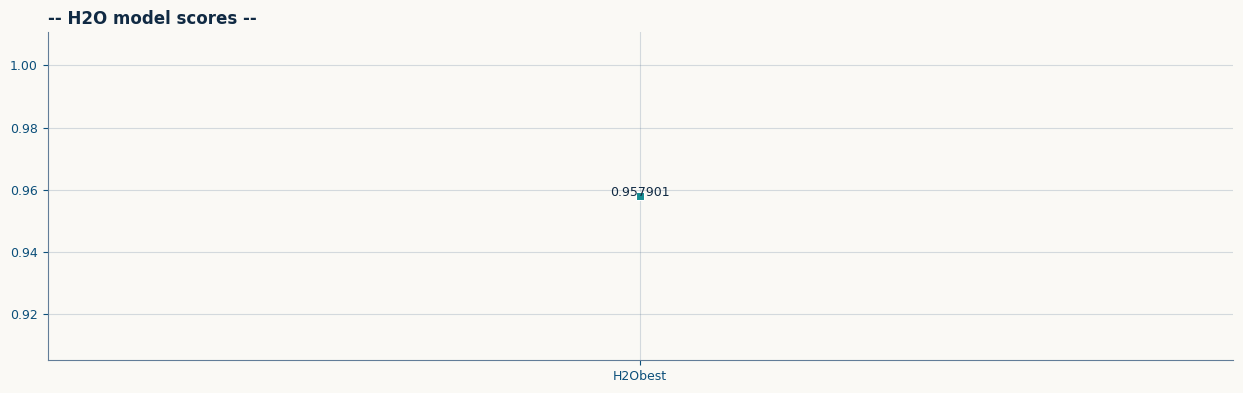

In [53]:
all_scores = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for x, y in v.items():
        if x == "score":
            all_scores[k] = y

plt.figure(figsize=(12.5, 4))
ax1 = sns.lineplot([*all_scores.values()], marker="s")

for i, s in enumerate([*all_scores.values()]):
    ax1.text(float(i), s+1e-7, s, ha="center", va="baseline")

# plt.ylim((0.96, 0.97))
# plt.legend(loc="best")
plt.xticks(range(len(all_scores)), [*all_scores.keys()], rotation=0)
plt.title("-- H2O model scores --", loc='left')

plt.tight_layout() 
plt.show()

H2Obest_957901 saved!


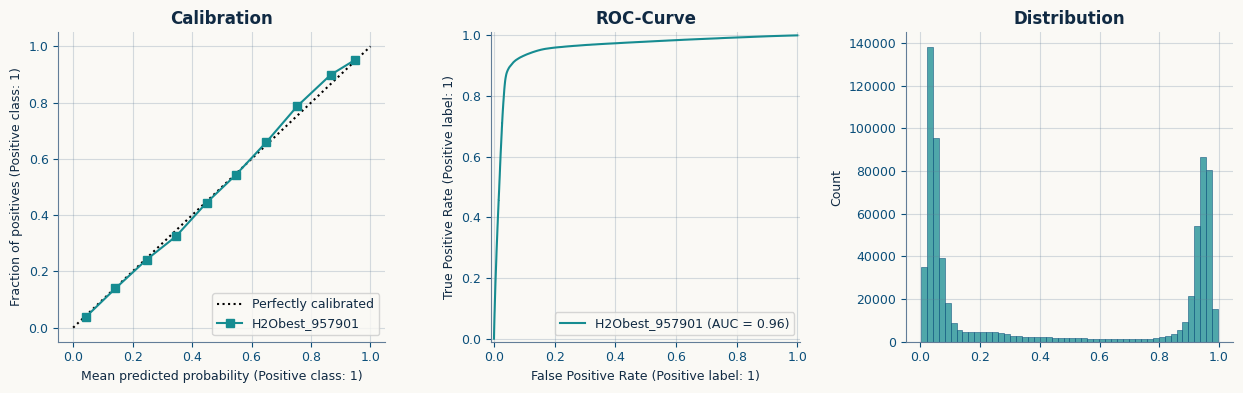

In [54]:
## -- Get oof predictions --
oof_predictions = []

for i, (k, v) in enumerate(all_predictions.items()):
    for key_, data_ in v.items():
        if key_ == "oof_preds":
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"oof_{n}.npy", data_)
            print(f"{n} saved!")

            ## -- Plot distributions --
            _, axs = plt.subplots(1, 3, figsize=(12.5, 4)) 
            CalibrationDisplay.from_predictions(train_X[TARGET], data_, n_bins=10, name=n, ax=axs[0])
            axs[0].set_title("Calibration")

            RocCurveDisplay.from_predictions(train_X[TARGET], data_, name=n, ax=axs[1])
            axs[1].set_title("ROC-Curve")

            sns.histplot(data_, ax=axs[2], bins=50)
            axs[2].set_title("Distribution")
            
            plt.tight_layout()
            plt.show()

            print()

In [55]:
## -- Save test predictions/submissions --
model_results = {}

for i, (k, v) in enumerate(all_predictions.items()):
    for j, (x, y) in enumerate(v.items()):
        if x == "test_preds":
            ## -- Base submission file --
            n = f"{k}_{str(all_scores[k]).split('.')[1]}"
            np.save(f"test_{n}.npy", y)

            submit[TARGET] = y
            submit.to_csv(f"submit_{n}.csv", index=False)
            print(f"{n:>17} saved! {y.shape}")

            model_results[n] = y

print()
model_results = pd.DataFrame(model_results)
model_results

   H2Obest_957901 saved! (299844,)



,H2Obest_957901
0,0.266138
1,0.863698
2,0.912335
3,0.072618
4,0.052262
...,...
299839,0.053609
299840,0.060587
299841,0.295530
299842,0.030023


# XAI

In [56]:
## -- Inspect model -- 
model_list = list(all_predictions.keys())
model_list

['H2Obest']

In [57]:
get_model = all_predictions[model_list[0]]
get_model["model"].leader

Model Details
=============
H2OXGBoostEstimator : XGBoost
Model Key: XGBoost_2_AutoML_10_20261031_184740


Model Summary: 
    number_of_trees
--  -----------------
    30

ModelMetricsBinomial: xgboost
** Reported on train data. **

MSE: 0.05801212465343075
RMSE: 0.24085706270199084
LogLoss: 0.2158774287934628
Mean Per-Class Error: 0.07250643115695302
AUC: 0.9653768776668893
AUCPR: 0.9557949285823558
Gini: 0.9307537553337786

Confusion Matrix (Act/Pred) for max f1 @ threshold = 0.4532366507524586
       0       1       Error    Rate
-----  ------  ------  -------  ------------------
0      292965  18472   0.0593   (18472.0/311437.0)
1      21277   226994  0.0857   (21277.0/248271.0)
Total  314242  245466  0.071    (39749.0/559708.0)

Maximum Metrics: Maximum metrics at their respective thresholds
metric                       threshold    value     idx
---------------------------  -----------  --------  -----
max f1                       0.453237     0.919494  196
max f2                       0.207661     0.93034   274
max f0point5                 0.690422     0.931929  136
max accuracy                 0.489185     0.929327  186
max precision                0.989057     0.998552  1
max recall                   0.0110769    1         397
max specificity              0.991689     0.999997  0
max absolute_mcc             0.489185     0.85668   186
max min_per_class_accuracy   0.361572     0.926459  222
max mean_per_class_accuracy  0.449542     0.927502  197
max tns                      0.991689     311436    0
max fns                      0.991689     247767    0
max fps                      0.00695337   311437    399
max tps                      0.0110769    248271    397
max tnr                      0.991689     0.999997  0
max fnr                      0.991689     0.99797   0
max fpr                      0.00695337   1         399
max tpr                      0.0110769    1         397

Gains/Lift Table: Avg response rate: 44.36 %, avg score: 44.36 %
group    cumulative_data_fraction    lower_threshold    lift       cumulative_lift    response_rate    score      cumulative_response_rate    cumulative_score    capture_rate    cumulative_capture_rate    gain      cumulative_gain    kolmogorov_smirnov
-------  --------------------------  -----------------  ---------  -----------------  ---------------  ---------  --------------------------  ------------------  --------------  -------------------------  --------  -----------------  --------------------
1        0.0100016                   0.982913           2.24436    2.24436            0.995534         0.986336   0.995534                    0.986336            0.0224472       0.0224472                  124.436   124.436            0.022367
2        0.0200015                   0.978955           2.24153    2.24295            0.994283         0.980776   0.994908                    0.983556            0.022415        0.0448623                  124.153   124.295            0.0446792
3        0.0300014                   0.97603            2.23509    2.24033            0.991424         0.977429   0.993747                    0.981514            0.0223506       0.0672128                  123.509   124.033            0.0668757
4        0.0400012                   0.973605           2.21576    2.23418            0.982848         0.974766   0.991022                    0.979827            0.0221572       0.0893701                  121.576   123.418            0.0887247
5        0.0500029                   0.971621           2.21898    2.23114            0.98428          0.972585   0.989674                    0.978378            0.0221935       0.111564                   121.898   123.114            0.110636
6        0.1                         0.964733           2.2056     2.21837            0.978345         0.967942   0.98401                     0.97316             0.110275        0.221838                   120.56    121.837            0.218964
7        0.150001                    0.959255 

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
XGBoost_2_AutoML_10_20261031_184740,0.958077,0.229505,0.942619,0.0768054,0.247834,0.0614219,31097,0.002826,XGBoost
GBM_1_AutoML_10_20261031_184740,0.957811,0.234097,0.942274,0.0766021,0.248829,0.061916,20228,0.009724,GBM
XGBoost_3_AutoML_10_20261031_184740,0.957674,0.232319,0.941277,0.0778129,0.249898,0.0624489,26020,0.002011,XGBoost
XGBoost_1_AutoML_10_20261031_184740,0.957504,0.231009,0.941908,0.076793,0.248239,0.0616225,44523,0.003611,XGBoost
GBM_4_AutoML_10_20261031_184740,0.957462,0.233591,0.941606,0.0771548,0.249442,0.0622215,16445,0.008405,GBM
GBM_2_AutoML_10_20261031_184740,0.957034,0.235241,0.941214,0.0793494,0.251886,0.0634465,19238,0.010121,GBM
DRF_1_AutoML_10_20261031_184740,0.956264,0.234438,0.939375,0.0767836,0.249631,0.0623156,38777,0.014907,DRF
GBM_3_AutoML_10_20261031_184740,0.956169,0.242256,0.939634,0.0791536,0.253884,0.0644572,11448,0.006423,GBM
XRT_1_AutoML_10_20261031_184740,0.954698,0.244877,0.937234,0.0812145,0.257022,0.0660605,48241,0.015195,DRF
GLM_1_AutoML_10_20261031_184740,0.921269,0.344908,0.90873,0.125685,0.312598,0.0977175,23229,0.000759,GLM


# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## XGBoost_2_AutoML_10_20261031_184740

,0,1,Error,Rate
0,72925.0,4934.0,0.0634,(4934.0/77859.0)
1,5601.0,56467.0,0.0902,(5601.0/62068.0)
Total,78526.0,61401.0,0.0753,(10535.0/139927.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

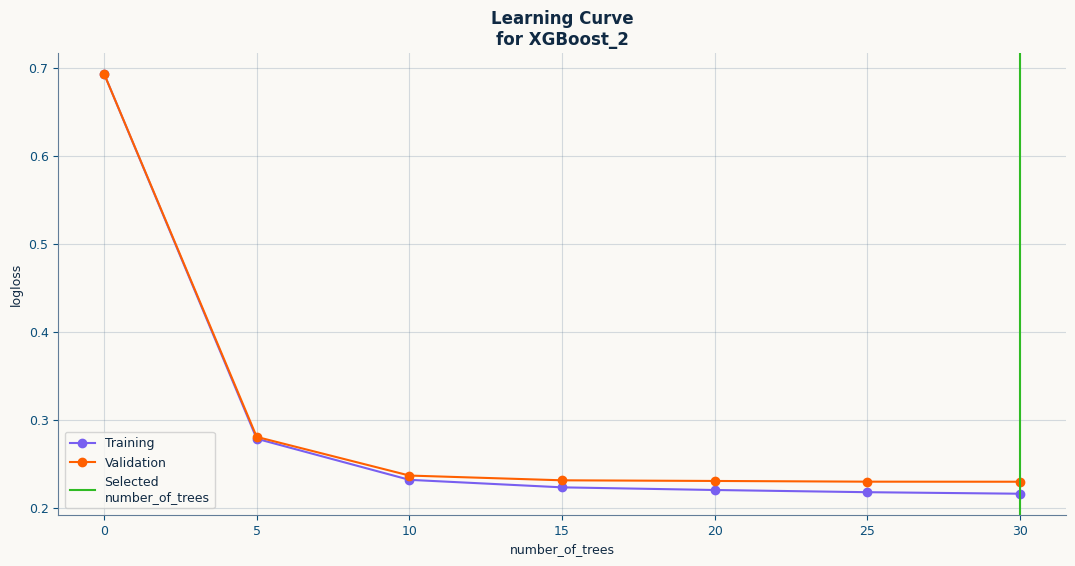

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

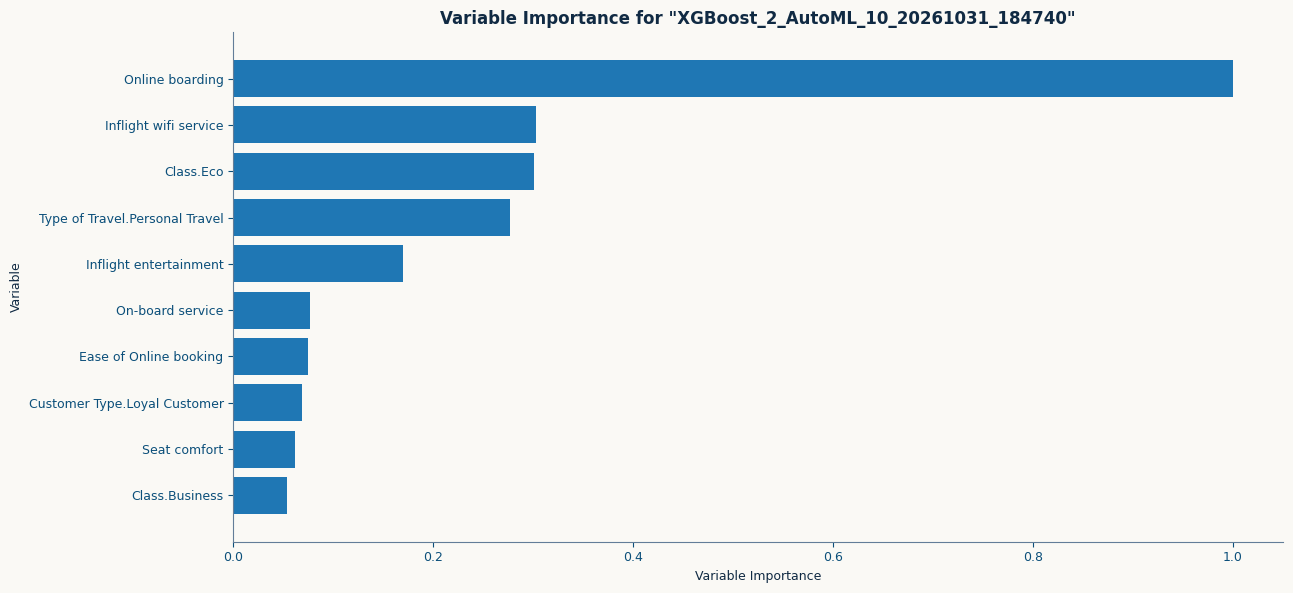

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

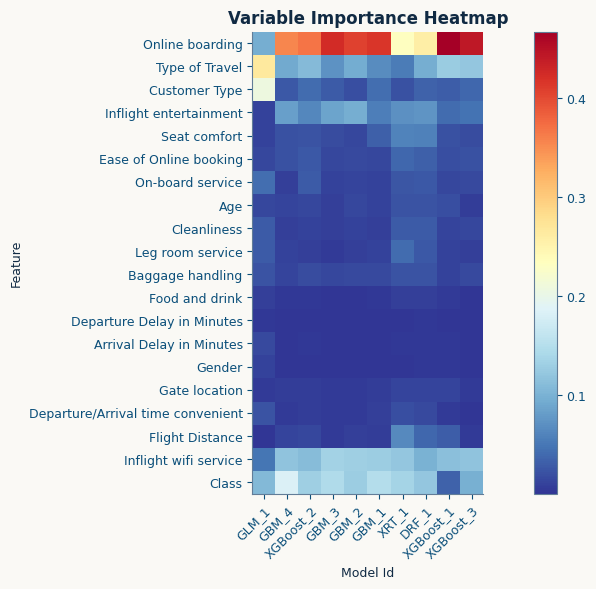

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

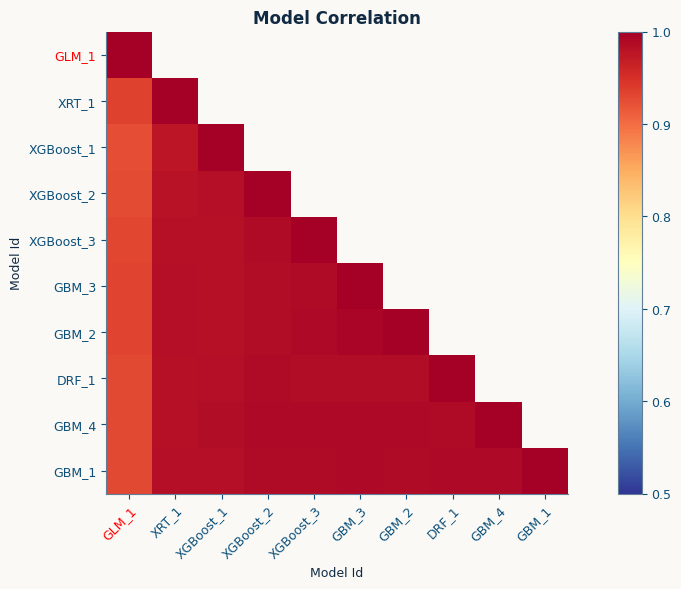

# Leaderboard

> Leaderboard shows models with their metrics. When provided with H2OAutoML object, the leaderboard shows 5-fold cross-validated metrics by default (depending on the H2OAutoML settings), otherwise it shows metrics computed on the frame. At most 20 models are shown by default.

model_id,auc,logloss,aucpr,mean_per_class_error,rmse,mse,training_time_ms,predict_time_per_row_ms,algo
XGBoost_2_AutoML_10_20261031_184740,0.958077,0.229505,0.942619,0.0768054,0.247834,0.0614219,31097,0.002826,XGBoost
GBM_1_AutoML_10_20261031_184740,0.957811,0.234097,0.942274,0.0766021,0.248829,0.061916,20228,0.009724,GBM
XGBoost_3_AutoML_10_20261031_184740,0.957674,0.232319,0.941277,0.0778129,0.249898,0.0624489,26020,0.002011,XGBoost
XGBoost_1_AutoML_10_20261031_184740,0.957504,0.231009,0.941908,0.076793,0.248239,0.0616225,44523,0.003611,XGBoost
GBM_4_AutoML_10_20261031_184740,0.957462,0.233591,0.941606,0.0771548,0.249442,0.0622215,16445,0.008405,GBM
GBM_2_AutoML_10_20261031_184740,0.957034,0.235241,0.941214,0.0793494,0.251886,0.0634465,19238,0.010121,GBM
DRF_1_AutoML_10_20261031_184740,0.956264,0.234438,0.939375,0.0767836,0.249631,0.0623156,38777,0.014907,DRF
GBM_3_AutoML_10_20261031_184740,0.956169,0.242256,0.939634,0.0791536,0.253884,0.0644572,11448,0.006423,GBM
XRT_1_AutoML_10_20261031_184740,0.954698,0.244877,0.937234,0.0812145,0.257022,0.0660605,48241,0.015195,DRF
GLM_1_AutoML_10_20261031_184740,0.921269,0.344908,0.90873,0.125685,0.312598,0.0977175,23229,0.000759,GLM


# Confusion Matrix

> Confusion matrix shows a predicted class vs an actual class.

## XGBoost_2_AutoML_10_20261031_184740

,0,1,Error,Rate
0,72925.0,4934.0,0.0634,(4934.0/77859.0)
1,5601.0,56467.0,0.0902,(5601.0/62068.0)
Total,78526.0,61401.0,0.0753,(10535.0/139927.0)


# Learning Curve Plot

> Learning curve plot shows the loss function/metric dependent on number of iterations or trees for tree-based algorithms. This plot can be useful for determining whether the model overfits.

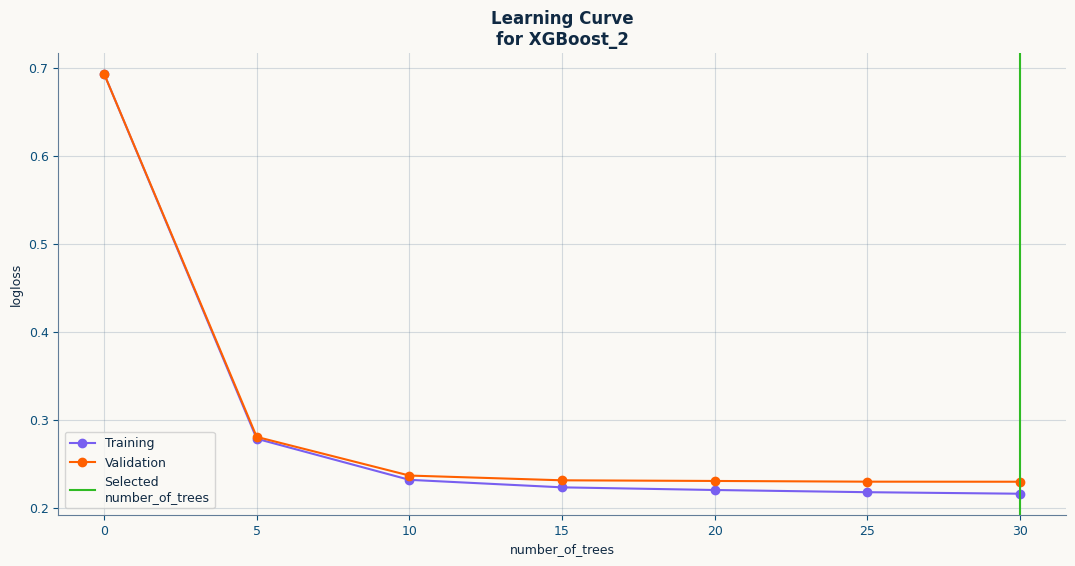

# Variable Importance

> The variable importance plot shows the relative importance of the most important variables in the model.

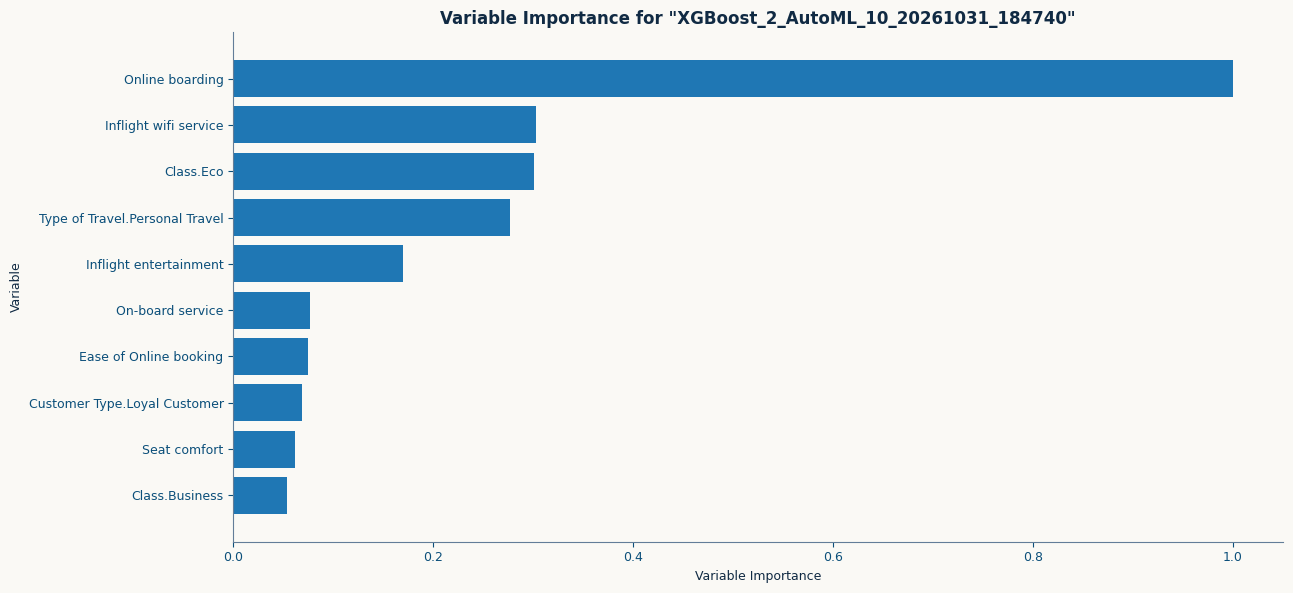

# Variable Importance Heatmap

> Variable importance heatmap shows variable importance across multiple models. Some models in H2O return variable importance for one-hot (binary indicator) encoded versions of categorical columns (e.g. Deep Learning, XGBoost). In order for the variable importance of categorical columns to be compared across all model types we compute a summarization of the the variable importance across all one-hot encoded features and return a single variable importance for the original categorical feature. By default, the models and variables are ordered by their similarity.

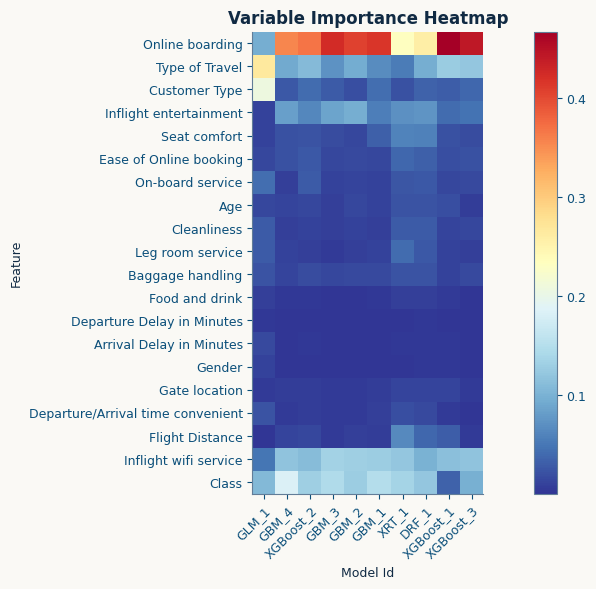

# Model Correlation

> This plot shows the correlation between the predictions of the models. For classification, frequency of identical predictions is used. By default, models are ordered by their similarity (as computed by hierarchical clustering). Interpretable models, such as GAM, GLM, and RuleFit are highlighted using red colored text.

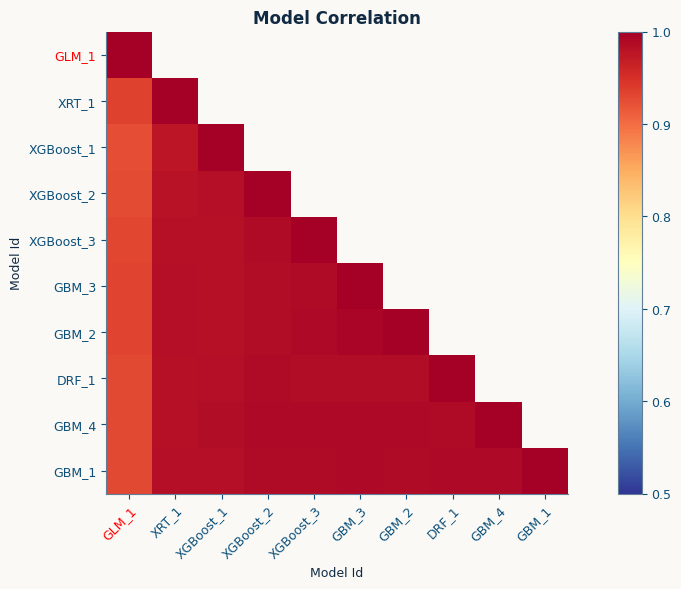

In [58]:
h2o.explain(
    get_model['model'], get_model['val_data'],
    exclude_explanations=[
        "pdp",
        "shap_summary", # Issues with shap display
    ],
    top_n_features=3,
    figsize=(13, 6),
)

In [ ]:
h2o.cluster().shutdown()

In [ ]:
# !rm -r /kaggle/working/ 

# HILLCLIMB

In [ ]:
# try:
#     from hillclimbers import climb_hill, partial
# except:
#     %pip install -q -U hillclimbers
#     from hillclimbers import climb_hill, partial

In [ ]:
def dataloader(filepath, train_prefix, test_prefix):    
    # Store dataframes in lists
    train_list = []
    test_list  = []

    print('Loading .npy files: ')
    for (root, dirs, files) in os.walk(filepath):
        # Filter files first to ensure accurate tqdm count
        npy_files = [f for f in sorted(files) if f.endswith('.npy')]
        
        for file in tqdm(npy_files):
            arr = np.load(os.path.join(root, file))
            base_name = file.replace('.npy', '')
            
            # Create the 3-column chunk
            new_cols = pd.DataFrame(
                arr, 
                columns=[f"{base_name}_c{c}" for c in range(3)]
            )
            
            if train_prefix in file:
                train_list.append(new_cols)
            elif test_prefix in file:
                test_list.append(new_cols)
    
    # Concatenate everything at once
    train_df = pd.concat(train_list, axis=1) if train_list else pd.DataFrame()
    test_df  = pd.concat(test_list, axis=1) if test_list else pd.DataFrame()

    train_df.columns = [c.replace('oof_', '') for c in train_df.columns]
    test_df.columns  = [c.replace('test_', '') for c in test_df.columns]
    
    return train_df, test_df, train_list

def rename_duplicate_cols(df: pd.DataFrame) -> pd.DataFrame:
    original_cols = list(df.columns)
    new_cols = []
    # Track how many times we've seen each original name
    seen = {}

    for col in tqdm(original_cols, desc="Fixing columns"):
        if col not in seen:
            # First occurrence: keep name unchanged
            seen[col] = 1
            new_cols.append(col)
        else:
            # Duplicate: append suffix _k where k starts at 0
            suffix = seen[col] - 1 # 0 for first duplicate, 1 for second,
            new_name = f"{col}_{suffix}"
            new_cols.append(new_name)
            seen[col] += 1

    # Apply new column names
    df_renamed = df.copy()
    df_renamed.columns = new_cols

    return df_renamed
    
print('Data loader function ready!')

In [ ]:
# OOF_PATH = "/kaggle/working/"
# oof_df, test_df, col_names = dataloader(OOF_PATH, "oof", "test")

# per_model_class_output = []
# desc = 'Extracting class names'

# for model in tqdm(col_names, total=len(col_names), desc=desc):
#     model.columns = [c.replace("oof_", "") for c in model.columns]
#     per_model_class_output.append(model.columns.tolist())

# ## -- Drop models if necessary --
# for c in oof_df.columns:
#     if "best" in c: #
#         oof_df.drop(columns=[c],  inplace=True)
#         test_df.drop(columns=[c], inplace=True)

# print("-"*50)
# ## -- Check for missingness --
# print(f"OOF  Null: {oof_df.isna().sum().sum()} | ",end="")
# print(f"TEST Null: {test_df.isna().sum().sum()}")
# print("-"*50)

# ## -- Apply column rename function --
# oof_df  = rename_duplicate_cols(oof_df)
# test_df = rename_duplicate_cols(test_df)

# print()
# print(f"{CFG['YELLOW']} • Columns updated: {oof_df.shape[1]}")

# display(oof_df.head(3))
# print()
# display(test_df.head(3))

In [ ]:
# %%time

# trn = pd.read_csv(PATH+"train.csv").drop(columns=['id'])
# pred_hc, oof_hc = climb_hill(
#                                train = train_X,
#                               target = TARGET,
#                          oof_pred_df = oof_df,
#                         test_pred_df = test_df,
#                            objective = "maximize",
#                          eval_metric = partial(roc_auc_score),
#                     # negative_weights = True,
#                     return_oof_preds = True,
#                            precision = 0.01,
#                            plot_hill = True,
#                            plot_hist = True,
# )

In [ ]:
# hc_score = str(round(roc_auc_score(train_X[TARGET], oof_hc), 5)).split('.')[1]
# print(f"Hillclimb score: {hc_score}")

# np.save(f"oof_{VERS}_hillclimb_{hc_score}_.npy", oof_hc)
# np.save(f"test_{VERS}_hillclimb_{hc_score}_.npy", pred_hc)

# submit[TARGET] = pred_hc
# submit.to_csv(f"submit_{VERS}_hillclimb_{hc_score}.csv", index=False)
# print(f"\n✅ Saved hillclimb ensemble!")

# submit.head(10)